# Is a learned warm start worth it: a network for the trap phases against a freeze with no network

**Question:** Does a network that predicts the trap phases make phase-fixed WGS converge faster, or does a simpler change, freezing the phase early with no network at all, explain the whole gain?

- **Level:** 4, Beyond the state of the art (claim BS-3, tested and refuted)
- **Prerequisites:** notebooks 01 and 02 of topic 01-fourier-optics, and notebooks 01 to 03 of this topic for what a released network is
- **Method run:** M07 (phase-fixed weighted Gerchberg-Saxton) and the B3 slot that wraps it; the reference is slmsuite's WGS-Kim
- **Reading time:** about 55 minutes; the notebook runs in about 90 seconds

## Objectives

Weighted Gerchberg-Saxton with a phase that is fixed after a few iterations is the practical method for arrays of hundreds or thousands of traps. Its starting hologram is random, and it needs about fifteen iterations to bring the traps within one percent of each other. The product proposed to shorten that with a network that predicts each trap's starting phase. The proposal was built, trained and measured, and it was refused. You will run the rule on the 1024-trap array of case C03 and see where its iterations go, measure the best start any network could give, run the rule's reference implementation on the same start, and then re-run the control that explained the network's gain: the same early freeze, a random start, no network. You finish knowing what the network was credited with and what it actually did.

## Setup

The notebook environment is pinned in `notebooks/requirements.txt` and built with `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows). The packages this notebook uses, with their exact pins:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2 slmsuite==0.5.0
```

DinHot publishes no package of its own: its methods live in `data-pipeline/pipeline/` and the notebook imports them by their path. slmsuite (MIT) is the pinned reference implementation of the rule. The next cell imports the tools, quiets the reference's per-object log line and prints the versions.

In [1]:
# the tools and their versions, then the pipeline's modules by path and the pinned reference implementation
import importlib.metadata as md
import json
import logging
import sys
import warnings
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

warnings.filterwarnings("ignore")
logging.disable(logging.INFO)  # the reference prints a timestamped line per object it builds
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases.build import setup_of, trapset_of
from pipeline.io.contract import read_cases
from pipeline.model.holo.core import forward, metrics
from pipeline.model.holo.core.geometry import focal_bin_m, input_amplitude
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.traps import Trap, TrapSet
from pipeline.model.holo.core.types import Budget, Target
from pipeline.model.holo.learned import generators
from pipeline.model.holo.learned.evaluation import first_below
from pipeline.model.holo.methods.baseline import m02_random_superposition, m07_phase_fixed_wgs
from pipeline.model.holo.methods.learned import b3_warm_start
from slmsuite.holography.algorithms import SpotHologram

for name in ("numpy", "matplotlib", "slmsuite"):
    print(name, md.version(name))

numpy 2.4.6
matplotlib 3.11.2
slmsuite 0.5.0


## Data

- Owner: this repository, https://github.com/fsantibanezleal/CEFOP_DinHot.
- Licence class: synthetic. Case C03 is written by the product (32 by 32 traps, 850 nm, a 256 by 256 pixel SLM), the geometries of the control are drawn by the product's seeded generators, and the record of the refused network is the product's own measurement, so no third-party dataset applies.
- Files read: `data/examples/cases.json` (case C03) and `data/derived/models/warmstart-model-rejected.json`, the committed record of the candidate network on 66 held-out geometries. No network file exists: the candidate was not released, so the record is read, as the claim under test, and never re-computed here.

In [2]:
# case C03, the large array of 1024 traps, and the committed record of the candidate that was tested and refused
records = {rec["case_id"]: rec for rec in read_cases(ROOT / "data" / "examples" / "cases.json")}
rec = records["C03_large_array"]
setup = setup_of(rec)
target = Target.from_traps(trapset_of(rec["target"]["traps"]))
claim = json.loads((ROOT / "data" / "derived" / "models" / "warmstart-model-rejected.json").read_text(encoding="utf-8"))
print(f"{len(target.traps)} traps on a {setup.n_pix} x {setup.n_pix} SLM with padding {setup.pad}, seed {rec['seed']}")
print("record of the candidate:", claim["slot"], "| held-out geometries:", claim["metrics"]["held_out_n"])

1024 traps on a 256 x 256 SLM with padding 2, seed 20261028
record of the candidate: warmstart-model | held-out geometries: 66


## Method

**The rule.** Phase-fixed WGS (Kim et al. 2019, https://doi.org/10.1364/OL.44.003178) keeps one weight $g_m$ per trap, updated each iteration from the amplitude $B_i(\mathbf u_m)$ the hologram makes at the trap,

$$g_i(\mathbf u_m) = \frac{\langle B_i\rangle_N}{B_i(\mathbf u_m)}\, g_{i-1}(\mathbf u_m), \qquad \mathcal F[A_{i+1} e^{i\phi_{i+1}}] = g_i T\, e^{i\psi_i},$$

where $T$ is the target amplitude and the focal phase $\psi_i$ follows the field for the first $N$ iterations and is then frozen at $\psi_N$. The paper uses $N = 12$. The product calls $N$ `n_fix`. Freezing the phase turns the later iterations into a nearly linear problem for the weights, which is why they converge fast, and also why they stop improving whatever the start was.

**The proposal, B3.** A permutation-equivariant network reads the trap list (positions in focal bins, depth in Rayleigh ranges, weight) and predicts one phase $\theta_m$ per trap. The starting hologram is the superposition with those phases, $\phi^{(0)}_j = \arg \sum_m \sqrt{w_m}\, e^{i(\Delta^m_j + \theta_m)}$, and M07 runs from it. The product's gap statement was that no source it read starts WGS from a network. The network was trained without labels, through a differentiable copy of the rule, so that it learns a start from which M07 converges sooner.

**The test.** Iterations to one percent of relative standard deviation of the trap intensities, $\sigma = 100\,\mathrm{std}(I)/\mathrm{mean}(I)$, on held-out geometries, with the final efficiency and uniformity held to within one percent. The criterion asked for a median at least two times lower than from a random start.

The first step runs the rule itself on case C03 from one random start, once with the paper's $N = 12$ and once with the phase frozen after 3 iterations. The random start is the superposition with random trap phases, which is what the engine's own method draws, and both runs and the later ones take it as an explicit start so that every comparison shares it.

In [3]:
# phase-fixed WGS (M07) on the 1024 traps from one random start, the phase frozen after 12 iterations and after 3
start = m02_random_superposition.run(setup, target, budget=Budget(1), rng=Rng(rec["seed"])).phi
runs = {}
for n_fix in (12, 3):
    runs[n_fix] = m07_phase_fixed_wgs.run(setup, target, budget=Budget(20), rng=Rng(1), init=start, n_fix=n_fix)
    last = runs[n_fix].history[-1]
    reached = first_below(runs[n_fix].history, 1.0, 20)
    print(f"freeze after {n_fix:2d}: 1 percent at iteration {reached}, final relative std {last['rel_std']:.2f} %, "
          f"efficiency {last['efficiency']:.3f}, uniformity {last['uniformity']:.3f}")

freeze after 12: 1 percent at iteration 15, final relative std 0.33 %, efficiency 0.794, uniformity 0.984
freeze after  3: 1 percent at iteration 21, final relative std 6.77 %, efficiency 0.764, uniformity 0.749


With the paper's freeze the spread falls below one percent at iteration 15 and ends at 0.33 percent, with efficiency 0.794 and uniformity 0.984. With the freeze after 3 iterations the run never reaches one percent in 20 iterations: it ends at 6.77 percent with efficiency 0.764 and uniformity 0.749. The next figure draws both curves.

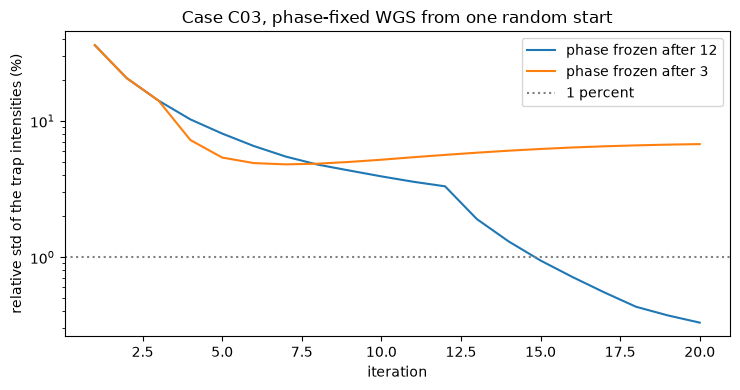

In [4]:
# the relative spread of the 1024 trap intensities against the iteration, for the two freeze points
fig, ax = plt.subplots(figsize=(7.5, 4))
for n_fix, res in runs.items():
    ax.semilogy(*zip(*[(h["iteration"], h["rel_std"]) for h in res.history]), label=f"phase frozen after {n_fix}")
ax.axhline(1.0, color="gray", linestyle=":", label="1 percent")
ax.set_xlabel("iteration")
ax.set_ylabel("relative std of the trap intensities (%)")
ax.set_title("Case C03, phase-fixed WGS from one random start")
ax.legend()
fig.tight_layout()
plt.show()

The twelve-iteration curve falls slowly and then drops by almost half in one step at iteration 13, the first iteration after the freeze; the early freeze curve flattens after 5 iterations, at about five percent, and drifts up to almost seven. The figure shows that the freeze is the lever of speed, and that the price of freezing early is a floor. It does not show whether a better start would remove the floor, which is what a network is supposed to provide. The next cell gives the rule the best start there is, the hologram that a 40-iteration run converged to, and runs it under both freeze points.

In [5]:
# the best start there is: the hologram a 40 iteration run converged to, handed to the same rule
long_run = m07_phase_fixed_wgs.run(setup, target, budget=Budget(40), rng=Rng(rec["seed"]), init=start)
oracle = {}
for n_fix in (12, 3):
    oracle[n_fix] = m07_phase_fixed_wgs.run(setup, target, budget=Budget(20), rng=Rng(1), init=long_run.phi,
                                            n_fix=n_fix)
    first = oracle[n_fix].history[0]
    reached = first_below(oracle[n_fix].history, 1.0, 20)
    print(f"converged start, freeze after {n_fix:2d}: relative std {first['rel_std']:.2f} % at iteration 1, "
          f"1 percent at iteration {reached}")

converged start, freeze after 12: relative std 14.36 % at iteration 1, 1 percent at iteration 13
converged start, freeze after  3: relative std 14.36 % at iteration 1, 1 percent at iteration 7


From a converged hologram the first iteration shows a relative spread of 14.36 percent, not the near-zero a converged hologram has: the rule restarts its weights at 1 and redoes the work of the first iterations. With the paper's freeze the run still needs 13 iterations to reach one percent, two fewer than from a random start; with the freeze after 3 it reaches one percent at iteration 7 and keeps going down. The next figure draws the two starts for both freezes.

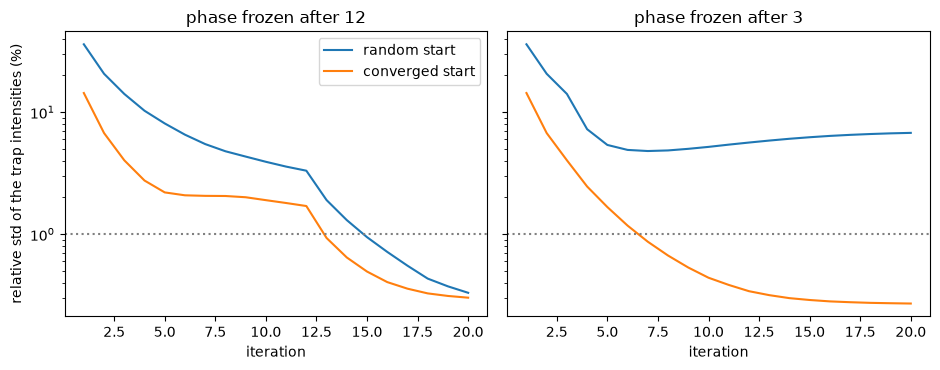

In [6]:
# random start against converged start, for both freeze points
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.8), sharey=True)
for ax, n_fix in zip(axes, (12, 3)):
    for label, res in (("random start", runs[n_fix]), ("converged start", oracle[n_fix])):
        ax.semilogy([h["iteration"] for h in res.history], [h["rel_std"] for h in res.history], label=label)
    ax.axhline(1.0, color="gray", linestyle=":")
    ax.set_title(f"phase frozen after {n_fix}")
    ax.set_xlabel("iteration")
axes[0].set_ylabel("relative std of the trap intensities (%)")
axes[0].legend()
fig.tight_layout()
plt.show()

On the left, the freeze after 12, the converged start lies below the random one for the first twelve iterations and then both fall together after the freeze to the same floor, so a perfect start saves little: the rule spends its first twelve iterations on a phase update that a start can shorten but not skip. On the right, the freeze after 3, a good start removes the floor (the orange curve keeps going down), and a random one does not (the blue curve stops at almost seven percent). This is the opening for a network: with an early freeze, a good enough start is worth a lot. The figure does not say that a network can supply such a start from the trap list alone, which is the claim that has to be measured.

## State of the art

The reference implementation of this rule is slmsuite's `WGS-Kim` (Kim et al. 2019, as implemented in slmsuite 0.5.0), which fixes the farfield phase after `fix_phase_iteration` iterations. The comparison is made on the same footing: the same 1024 traps on the same padded grid, the same input beam amplitude, the same random start handed over as the initial phase, and the same ruler, because the phase that slmsuite holds after every iteration is scored here with DinHot's own trap metrics. Where the two disagree, the disagreement is a property of the implementations and not of the measure.

In [7]:
# the reference, slmsuite's WGS-Kim, on the same traps, input beam and random start; its phase is kept each iteration
n = setup.n_fft
bins = np.vstack(forward.trap_bins(setup, target.traps)).astype(float)
phases = []


def keep_phase(hologram):
    phases.append(np.asarray(hologram.get_phase()).copy())


holo = SpotHologram(shape=(n, n), spot_vectors=bins, basis="knm", slm_shape=(setup.n_pix,) * 2,
                    amp=input_amplitude(setup), phase=start)
holo.optimize(method="WGS-Kim", maxiter=20, verbose=False, callback=keep_phase, fix_phase_iteration=12)
print("phases kept:", len(phases), "| shape", phases[0].shape)

phases kept: 20 | shape (256, 256)


The reference holds one phase per iteration, 20 of them, each 256 by 256. The next cell scores them with the engine and reports the iteration at which each implementation first reaches one percent.

In [8]:
# score every slmsuite iteration with the engine's own trap metrics, so both methods are read by one ruler
def spread_of(phi):
    field = forward.trap_fields_from_fft(forward.fft_focal_field(phi, setup), setup, target.traps)
    return metrics.rel_std(metrics.trap_intensities(field))


slm_curve = [spread_of(p) for p in phases]
slm_hist = [{"iteration": k + 1, "rel_std": s} for k, s in enumerate(slm_curve)]
reached = first_below(slm_hist, 1.0, 20)
print(f"slmsuite WGS-Kim: 1 percent at iteration {reached}, final relative std {slm_curve[-1]:.2f} %")
print(f"DinHot M07:       1 percent at iteration {first_below(runs[12].history, 1.0, 20)}, "
      f"final relative std {runs[12].history[-1]['rel_std']:.2f} %")

slmsuite WGS-Kim: 1 percent at iteration 18, final relative std 0.61 %
DinHot M07:       1 percent at iteration 15, final relative std 0.33 %


The reference reaches one percent at iteration 18 and ends at 0.61 percent; the DinHot rule reaches it at 15 and ends at 0.33 percent. Both implementations show the same structure, a slow fall and a drop right after iteration 12. They differ in details that the papers leave open: the dossier of the product records that Kim et al. do not define the amplitude $B_i$ that the weights use, and DinHot's rule uses the field amplitude, as in its M06, while slmsuite weights with its own feedback exponent. The next figure draws both.

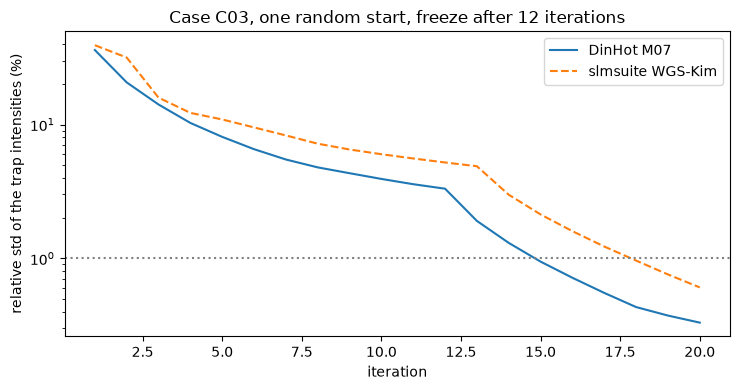

In [9]:
# the two implementations of the same rule, side by side
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.semilogy([h["iteration"] for h in runs[12].history], [h["rel_std"] for h in runs[12].history], label="DinHot M07")
ax.semilogy(range(1, len(slm_curve) + 1), slm_curve, "--", label="slmsuite WGS-Kim")
ax.axhline(1.0, color="gray", linestyle=":")
ax.set_xlabel("iteration")
ax.set_ylabel("relative std of the trap intensities (%)")
ax.set_title("Case C03, one random start, freeze after 12 iterations")
ax.legend()
fig.tight_layout()
plt.show()

The two curves agree on the shape and differ by a few iterations in where they cross one percent and by less than a factor of two in the floor after 20 iterations. The figure shows that the rule's behaviour does not depend on the implementation, so what follows is a statement about the rule and not about DinHot's code; it does not show which of the two is closer to the paper's hardware. With the state of the art in hand, the claim can be tested.

## Beyond the state of the art

**BS-3, the claim:** a network that predicts the trap phases starts phase-fixed WGS from a better hologram, so the rule needs at least two times fewer iterations to one percent on geometries the network never saw. The committed record is the measurement of the candidate that was trained for 6000 steps (a set transformer of 80.8 thousand parameters, a 339 kilobyte graph) with the freeze after 3 iterations, against a random start with the paper's freeze after 12. The next cell reads the record's medians.

In [10]:
# the claim that was tested: the committed medians of the trained candidate on held-out geometries
iters = claim["metrics"]["iterations_to_1pct"]
for arm, label in (("random", "random start, freeze 12"), ("model", "network start, freeze 3")):
    q = iters[arm]
    print(f"{label}: median {q['median']} iterations (q1 {q['q1']}, q3 {q['q3']})")
print("ratio of medians:", claim["ratio_random_over_model_median_iterations"], "| the criterion asked for 2")
gap = claim["final_metrics_relative_difference_of_medians"]["efficiency"]
print("final efficiency differs by", round(100 * gap, 1), "percent")
ctl = claim["control_without_the_network"]
for arm, (median, _q3) in ctl["median_and_q3_iterations"].items():
    print(f"the record's own control, 30 geometries: {arm:15s} median {median} iterations, "
          f"never reaching 1 percent {ctl['share_never_reaching_1pct'][arm]:.1%}")

random start, freeze 12: median 14.0 iterations (q1 13.0, q3 15.0)
network start, freeze 3: median 8.0 iterations (q1 5.0, q3 61.0)
ratio of medians: 1.75 | the criterion asked for 2
final efficiency differs by 4.2 percent
the record's own control, 30 geometries: random_nfix12   median 14.0 iterations, never reaching 1 percent 6.7%
the record's own control, 30 geometries: random_nfix3    median 9.0 iterations, never reaching 1 percent 40.0%
the record's own control, 30 geometries: model_nfix3     median 16.5 iterations, never reaching 1 percent 46.7%


The candidate reached one percent in a median of 8 iterations against 14 from a random start, a ratio of 1.75 where the criterion asked for 2, and its final efficiency differed by 4.2 percent where one percent was allowed. The upper quartile is 61 iterations, which means that more than a quarter of the geometries never reached one percent within the budget. The comparison has a confound the record states: the network arm froze after 3 iterations and the random arm after 12. The record's own control removes it on 30 geometries, and its last lines show the result: with the same freeze after 3, a random start has a median of 9.0 iterations, and the network start 16.5, with 40.0 and 46.7 percent of the runs never reaching one percent. That control is a committed measurement. The notebook re-runs it, on ten dense two-dimensional geometries (30 to 100 traps) from the product's generators on C03's optics with 64 by 64 pixels to keep the run short, and adds the intermediate freeze.

In [11]:
# ten dense 2D geometries from the product's generators, on C03's optics with 64 x 64 pixels, to keep the run short
small = replace(setup, n_pix=64)
bin_m = focal_bin_m(small)
gen = np.random.default_rng(20261028)
geometries = []
while len(geometries) < 10:
    pts = generators.sample_traps(gen, half_field=56.0, family=str(gen.choice(["grid", "hex", "ring", "random"])))
    if 30 <= len(pts) <= 100:
        traps_g = TrapSet(Trap(i, r[0] * bin_m, r[1] * bin_m, 0.0, r[3]) for i, r in enumerate(pts))
        geometries.append(Target.from_traps(traps_g))
print("traps per geometry:", [len(g.traps) for g in geometries])

traps per geometry: [39, 67, 64, 48, 93, 83, 99, 63, 81, 31]


The geometries come from the grid, hexagonal, ring and random families of the generator, the regular and irregular arrays the candidate was trained on; none has a depth, because the early freeze is tested in the plane. The next cell runs three freeze points on each geometry with two seeds, 60 runs in all, and gives every arm the same random start for one geometry and seed.

In [12]:
# three freeze points on every geometry and two seeds: the same random start in every arm of one geometry and seed
arms = {12: [], 6: [], 3: []}
for target_g in geometries:
    for seed in (301, 302):
        for n_fix in arms:
            res = m07_phase_fixed_wgs.run(small, target_g, budget=Budget(20), rng=Rng(seed), n_fix=n_fix)
            last = res.history[-1]
            arms[n_fix].append((first_below(res.history, 1.0, 20), last["efficiency"], last["rel_std"]))
for n_fix, rows_n in arms.items():
    it, eff, spread = (np.array(col) for col in zip(*rows_n))
    print(f"freeze {n_fix:2d}: median iterations {np.median(it):4.1f}, never reach 1 percent {np.mean(it > 20):4.0%}, "
          f"median final efficiency {np.median(eff):.3f}, median final relative std {np.median(spread):.3f} %")

freeze 12: median iterations 13.0, never reach 1 percent  10%, median final efficiency 0.769, median final relative std 0.109 %
freeze  6: median iterations  8.5, never reach 1 percent  30%, median final efficiency 0.755, median final relative std 0.311 %
freeze  3: median iterations  9.0, never reach 1 percent  40%, median final efficiency 0.741, median final relative std 0.745 %


With the paper's freeze after 12 iterations the median is 13.0 iterations and 10 percent of the 20 runs never reach one percent within 20 iterations. Freezing after 6 gives a median of 8.5 and 30 percent never reach; freezing after 3 gives 9.0, which is the speed the network showed (8) and the median of the record's own control, and 40 percent never reach. The early freeze shows its cost in the end state: the median efficiency falls from 0.769 to 0.755 to 0.741 as the freeze moves earlier, about 4 percent, which is the 4.2 percent the record counts against the network, and the median final spread grows from 0.109 to 0.311 to 0.745 percent. The next figure draws every run.

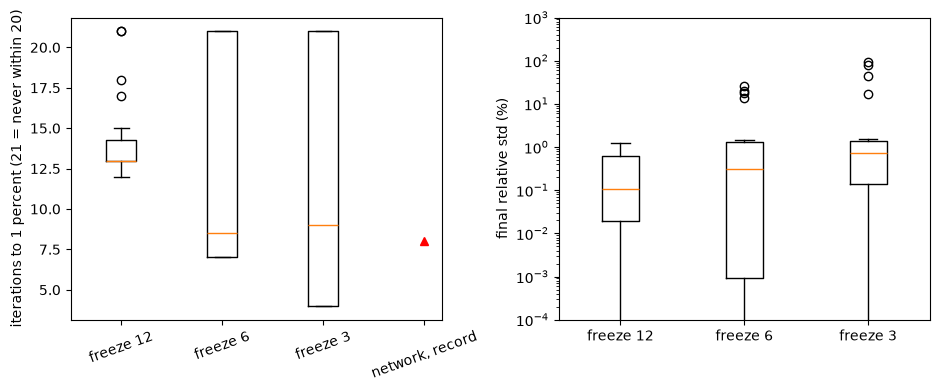

In [13]:
# the iterations to 1 percent and the final spread of every run, by freeze point, and the candidate's record
fig, axes = plt.subplots(1, 2, figsize=(9.5, 4))
labels = [f"freeze {n}" for n in arms]
axes[0].boxplot([[r[0] for r in arms[n]] for n in arms], tick_labels=labels, positions=[1, 2, 3])
axes[0].plot([4], [iters["model"]["median"]], "r^")
axes[0].set_xticks([1, 2, 3, 4], labels + ["network, record"])
axes[0].set_ylabel("iterations to 1 percent (21 = never within 20)")
axes[0].tick_params(axis="x", labelrotation=20)
axes[1].boxplot([[r[2] for r in arms[n]] for n in arms], tick_labels=labels)
axes[1].set_yscale("log")
axes[1].set_ylim(1e-4, 1e3)
axes[1].set_ylabel("final relative std (%)")
fig.tight_layout()
plt.show()

On the left, the iterations to one percent fall from the freeze after 12 to the freeze after 6, and the freeze after 3 is no faster than the freeze after 6 at the median, and the boxes of both reach the ceiling, 21 on this axis meaning never reached within 20 iterations. The red triangle, the network's recorded median of 8, lies inside the spread of the control's median for the same freeze, 9.0 here. On the right, the final spread on a log scale rises with the earlier freeze, so the speed is paid for in the quality of the end state. The figure shows that whatever speed the candidate network showed is available without it, from the freeze alone, and that the freeze trades failed runs and efficiency for it. It does not show that no network could help, since a different training or labels could still supply a start that removes the floor, as the converged start did in the first part. The last check is the product's own behaviour: B3, called with no released model, must answer as a random start, and nothing in the repository may claim that the network exists.

In [14]:
# with no released model the slot answers with the random start: B3 and M07 give the very same phase
probe = geometries[0]
b3_run = b3_warm_start.run(small, probe, budget=Budget(10), rng=Rng(301))
m07_run = m07_phase_fixed_wgs.run(small, probe, budget=Budget(10), rng=Rng(301), form="point")
same = bool(np.array_equal(b3_run.phi, m07_run.phi))
print("B3 provenance:", b3_run.meta["provenance"], "| same phase as M07:", same)
print("a released warmstart-model graph exists:", (ROOT / "models" / "warmstart-model.onnx").exists())

B3 provenance: baseline | same phase as M07: True
a released warmstart-model graph exists: False


## Results

**Answer:** No: the gain is explained by a simpler change. On held-out geometries the refused network needed a median of 8 iterations to one percent against 14 from a random start (ratio 1.75), but it also froze the phase after 3 iterations where the random arm froze after 12. The control with no network, a random start frozen after 3 iterations, needs a median of 9.0 iterations on the ten geometries of the notebook, against 13.0 with the paper's freeze, and a freeze after 6 iterations needs 8.5. The record's own control on 30 geometries gives 9.0 for the random start and 16.5 for the network at the same freeze, so the network added nothing over a random start. The freeze, not the start, buys the speed, and it costs convergence: 40 percent of the early-freeze runs here never reached one percent (40.0 percent in the record's control, 46.7 percent for the network) and the median final efficiency fell from 0.769 to 0.741. The best possible start does not rescue the paper's freeze, which still needs 13 iterations from a converged hologram on case C03, and it does help the early freeze, which then reaches one percent at iteration 7. The B3 slot answers with the random start while no model is released, and no graph exists, which is the state the product records: BS-3 is reported as tested and refuted.

What the notebook does not show: the network's own per-geometry numbers (the record keeps medians and quartiles), geometries with a depth, or a network trained on converged labels. The record states these as design questions for a new proposal, not as tuning of this one. The control here is small, ten geometries and two seeds on a 64 by 64 pixel SLM, and its medians agree with the 30-geometry control of the record.

## Summary

A start can only help a method whose later iterations still depend on it. Phase-fixed WGS with the paper's twelve free iterations erases most of a start's advantage, and with an early freeze it is the freeze that converges fast and the start that decides whether the floor is low. A network that predicts trap phases from the trap list did not supply a start good enough to lower the floor, and its apparent speed-up was reproduced by a random start with the same freeze and no network. The reference implementation, slmsuite's WGS-Kim, confirms that the rule and the numbers do not depend on DinHot's code. The product therefore ships no warm-start model and reports BS-3 as a measured negative; the next proposal in this direction would have to start from converged labels or change the freeze rule, and would be judged against the control that this notebook runs.

## References

- Kim, Kim, Lee and Ahn, "Gerchberg-Saxton algorithm with phase fixing for holographic optical tweezers arrays", Optics Letters 44, 3178 (2019), https://doi.org/10.1364/OL.44.003178.
- Eybposh et al., "DeepCGH: 3D computer-generated holography using deep learning", Optics Express 28, 26636 (2020), https://doi.org/10.1364/OE.399624.
- Ren et al., a generative network for holographic optical tweezers (2024), https://arxiv.org/abs/2401.06014, the work the product's gap statement compared against.
- Di Leonardo, Ianni and Ruocco, "Computer generation of optimal holograms for optical trap arrays", Optics Express 15, 1913 (2007), https://doi.org/10.1364/OE.15.001913.
- slmsuite 0.5.0 (MIT), https://github.com/slmsuite/slmsuite, the pinned reference implementation.
- The product's measured record of the refused candidate, `data/derived/models/warmstart-model-rejected.json`.